# Model 01 — Classifying UAV reliability condition from Commander eye tracking

**Input:** `data/eye_features_by_block.csv` (from `feature_extraction/01_eye_features.ipynb`).
**Targets:** (1) reliability condition — High-High (HH), Mixed (M), Low-Low (LL); (2) HH vs M only.

Contents
1. Data and within-Commander centering
2. Candidate models and nested cross-validation
3. Model comparison and pre-specified selection rule
4. Feature-set comparison (selected model)
5. Confusion matrix and ROC curves
6. Interpretation — permutation importance and SHAP
7. Secondary analysis: HH vs M (same comparison → selection → interpretation)
8. Feature-level linear mixed-effects models (descriptive)

All performance numbers come from Commanders the model never saw: folds are grouped by Commander, and each model's
hyperparameters are tuned in an inner loop that only sees the training Commanders.

In [1]:
import os
from pathlib import Path
# Run from anywhere inside the repository: paths below are relative to the repository root
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "feature_extraction").is_dir())
os.chdir(REPO)

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import (balanced_accuracy_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, get_scorer)
warnings.filterwarnings("ignore", category=UserWarning)
os.makedirs("figures/01_reliability_eye_tracking", exist_ok=True)

DATA_PATH = "data/eye_features_by_block.csv"
N_REPEATS = 10                  # repeated outer splits of Commanders
EQUIV_MARGIN = 0.02             # balanced-accuracy margin treated as a tie (see Section 3)
CLASS_NAMES = ["High-High", "Mixed", "Low-Low"]

## 1. Data and within-Commander centering

Centering subtracts each Commander's own mean (over their three blocks) from every feature, so the model compares
a block with the same person's other blocks rather than with other people. Only Commanders with all three blocks are
kept, because centering is not meaningful for a Commander with one or two blocks.

`pupil_mean_wp` (pupil relative to the person's mean) is dropped here: after centering it is identical to `pupil_mean`.

In [2]:
feat = pd.read_csv(DATA_PATH)

FEATURES = ["North_dwell_frac", "South_dwell_frac", "North_fix_rate", "South_fix_rate",
            "North_fix_dur_mean", "South_fix_dur_mean",
            "pupil_mean", "pupil_sd", "blink_frac", "fix_rate", "fix_dur_mean",
            "sac_rate", "sac_amp_mean", "sac_peakvel_px_mean", "sac_dur_mean",
            "SGE", "GTE", "p_N_to_S", "p_S_to_N", "NS_switch_rate"]
TRANSITIONS = ["SGE", "GTE", "p_N_to_S", "p_S_to_N", "NS_switch_rate"]

n_blocks = feat.groupby("ID")["Reliability"].nunique()
data = feat[feat["ID"].isin(n_blocks[n_blocks == 3].index)].reset_index(drop=True)
data["condition"] = data["Reliability"].map({"HH": 0, "M": 1, "LL": 2})

def center_within(df, cols):
    out = df.copy()
    for c in cols:
        out[c + "_c"] = out[c] - out.groupby("ID")[c].transform("mean")
    return out

data = center_within(data, FEATURES)
X_COLS = [f + "_c" for f in FEATURES]
print(f"{len(feat)} blocks in file -> {len(data)} blocks from {data['ID'].nunique()} Commanders with all three blocks")

140 blocks in file -> 135 blocks from 45 Commanders with all three blocks


## 2. Candidate models and nested cross-validation

| Model | What it is | Tuned in the inner loop |
|---|---|---|
| Baseline | always predicts class proportions; shows chance level | nothing |
| Logistic regression | linear model on standardised features, L2 penalty | `C` (smaller = stronger penalty) |
| Random forest | average of 300 decision trees on random subsets | tree depth, minimum samples per leaf |
| XGBoost | 300 small trees added one after another, each correcting the last | tree depth, minimum child weight, L2 penalty |

The grids are the same for both targets and were fixed before running.

- **Outer loop:** 5 folds grouped by Commander, repeated `N_REPEATS` times. The same splits are used for every model,
  so models can be compared repeat by repeat.
- **Inner loop:** within each outer training set, a 5-fold grouped grid search picks the hyperparameters (scored by AUC).
- **Metrics:** balanced accuracy (chance = 1 / number of classes), macro-F1, AUC (one-vs-rest for 3 classes; chance = 0.5),
  and training balanced accuracy (the gap to the test score indicates overfitting).

In [3]:
MODELS = {
    "Baseline": (DummyClassifier(strategy="prior"), {}),
    "Logistic regression": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
                            {"logisticregression__C": [0.01, 0.03, 0.1, 0.3, 1, 3]}),
    "Random forest": (RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1),
                      {"max_depth": [2, 3, 5], "min_samples_leaf": [3, 8, 15]}),
    "XGBoost": (XGBClassifier(n_estimators=300, learning_rate=0.03, random_state=0, n_jobs=1),
                {"max_depth": [1, 2, 3], "min_child_weight": [1, 5], "reg_lambda": [1, 10]}),
}
SIMPLICITY = ["Logistic regression", "Random forest", "XGBoost"]   # simplest first


def nested_cv(model_name, df, features, target, n_repeats=N_REPEATS):
    est, grid = MODELS[model_name]
    X, y, g = df[features], df[target], df["ID"]
    k = y.nunique()
    scoring = "roc_auc" if k == 2 else "roc_auc_ovr"
    rows, chosen, preds = [], [], []
    proba_mean = np.zeros((len(y), k))
    for rep in range(n_repeats):
        outer = GroupKFold(n_splits=5, shuffle=True, random_state=rep)
        proba, train_bal = np.zeros((len(y), k)), []
        for tr, te in outer.split(X, y, g):
            if grid:
                inner = GroupKFold(n_splits=5, shuffle=True, random_state=100 + rep)
                m = GridSearchCV(clone(est), grid, cv=inner, scoring=scoring)
                m.fit(X.iloc[tr], y.iloc[tr], groups=g.iloc[tr])          # tuning sees training Commanders only
                chosen.append(str(m.best_params_))
            else:
                m = clone(est).fit(X.iloc[tr], y.iloc[tr])
            proba[te] = m.predict_proba(X.iloc[te])                       # predictions for unseen Commanders
            train_bal.append(balanced_accuracy_score(y.iloc[tr], m.predict(X.iloc[tr])))
        pred = proba.argmax(axis=1)
        auc = roc_auc_score(y, proba[:, 1]) if k == 2 else roc_auc_score(y, proba, multi_class="ovr")
        rows.append({"repeat": rep, "train_bal_acc": np.mean(train_bal),
                     "bal_acc": balanced_accuracy_score(y, pred),
                     "macro_F1": f1_score(y, pred, average="macro"), "AUC": auc})
        preds.append(pred)
        proba_mean += proba / n_repeats
    return {"scores": pd.DataFrame(rows), "chosen": pd.Series(chosen, dtype=str).value_counts(),
            "preds": np.array(preds), "proba": proba_mean, "y": y.to_numpy()}


def compare_models(df, features, target):
    results = {name: nested_cv(name, df, features, target) for name in MODELS}
    tab = pd.DataFrame({name: {"bal_acc": r["scores"]["bal_acc"].mean(), "bal_acc_SD": r["scores"]["bal_acc"].std(),
                               "macro_F1": r["scores"]["macro_F1"].mean(), "AUC": r["scores"]["AUC"].mean(),
                               "AUC_SD": r["scores"]["AUC"].std(),
                               "train_bal_acc": r["scores"]["train_bal_acc"].mean(),
                               "train_test_gap": (r["scores"]["train_bal_acc"] - r["scores"]["bal_acc"]).mean()}
                        for name, r in results.items()}).T
    return results, tab


def select_model(results, margin=EQUIV_MARGIN):
    # Simplest model whose mean balanced accuracy is within `margin` of the best model
    means = pd.Series({m: results[m]["scores"]["bal_acc"].mean() for m in SIMPLICITY})
    best = means.idxmax()
    for m in SIMPLICITY:
        if means[best] - means[m] <= margin:
            return m, best

## 3. Model comparison and selection rule

**Selection rule (fixed before looking at results):** primary metric is held-out balanced accuracy. Choose the
**simplest** model (logistic regression < random forest < XGBoost) whose mean balanced accuracy is within
`EQUIV_MARGIN` = 0.02 of the best model. Differences smaller than this are within the split-to-split variation of
this sample (SD across repeats ≈ 0.03), so they are treated as ties and the more interpretable model wins.

The paired table shows each model minus the best model, repeat by repeat (same splits). Repeats reuse the same
Commanders, so their spread understates true uncertainty; read it as stability, not as a significance test.

Choosing a model after seeing nested scores adds a small optimistic bias to the chosen model's score; with three
candidates and near-equal scores this is small, and the rule limits it.

In [4]:
res_3way, tab_3way = compare_models(data, X_COLS, "condition")
tab_3way.round(3)

,bal_acc,bal_acc_SD,macro_F1,AUC,AUC_SD,train_bal_acc,train_test_gap
Baseline,0.333,0.000,0.167,0.500,0.000,0.333,0.000
Logistic regression,0.816,0.029,0.817,0.920,0.014,0.915,0.099
Random forest,0.815,0.016,0.814,0.923,0.006,0.931,0.116
XGBoost,0.790,0.031,0.791,0.903,0.018,0.967,0.177


In [5]:
def paired_differences(results):
    best = max(SIMPLICITY, key=lambda m: results[m]["scores"]["bal_acc"].mean())
    out = {}
    for m in SIMPLICITY:
        d = results[m]["scores"][["bal_acc", "AUC"]] - results[best]["scores"][["bal_acc", "AUC"]]
        out[m] = {"bal_acc_diff": d["bal_acc"].mean(), "bal_acc_diff_min": d["bal_acc"].min(),
                  "bal_acc_diff_max": d["bal_acc"].max(), "AUC_diff": d["AUC"].mean(),
                  "repeats_better_or_equal_%": 100 * (d["bal_acc"] >= 0).mean()}
    return pd.DataFrame(out).T

SELECTED, BEST_RAW = select_model(res_3way)
print(f"highest balanced accuracy: {BEST_RAW} | selected by rule: {SELECTED}")
paired_differences(res_3way).round(3)

highest balanced accuracy: Logistic regression | selected by rule: Logistic regression


,bal_acc_diff,bal_acc_diff_min,bal_acc_diff_max,AUC_diff,repeats_better_or_equal_%
Logistic regression,0.000,0.000,0.000,0.000,100.0
Random forest,-0.001,-0.067,0.030,0.003,60.0
XGBoost,-0.026,-0.074,0.037,-0.017,20.0


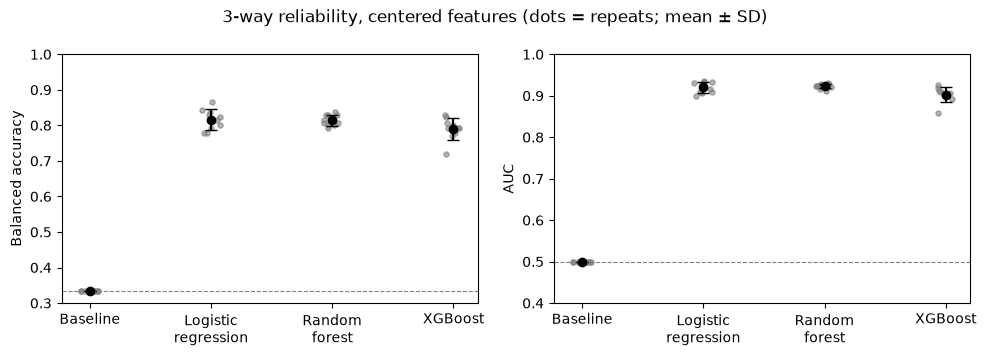

In [6]:
def plot_comparison(results, title, fname):
    names = list(results)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    for ax, metric, chance in [(axes[0], "bal_acc", None), (axes[1], "AUC", 0.5)]:
        vals = [results[n]["scores"][metric] for n in names]
        for i, v in enumerate(vals):
            ax.scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-0.08, 0.08, len(v)), v,
                       s=14, color="grey", alpha=0.6)
            ax.errorbar(i, v.mean(), yerr=v.std(), fmt="o", color="black", capsize=4)
        if chance is None:
            chance = 1 / len(np.unique(results[names[0]]["y"]))
        ax.axhline(chance, ls="--", color="grey", lw=0.8)
        ax.set_xticks(range(len(names))); ax.set_xticklabels([n.replace(" ", "\n") for n in names])
        ax.set_ylabel({"bal_acc": "Balanced accuracy", "AUC": "AUC"}[metric])
        ax.set_ylim(0.3 if metric == "bal_acc" else 0.4, 1.0)
    fig.suptitle(title + " (dots = repeats; mean ± SD)")
    fig.tight_layout(); fig.savefig(fname, dpi=200); plt.show()

plot_comparison(res_3way, "3-way reliability, centered features", "figures/01_reliability_eye_tracking/model_comparison_3way.png")

In [7]:
print("Hyperparameters chosen by the inner loop for", SELECTED, f"({N_REPEATS * 5} outer folds):")
res_3way[SELECTED]["chosen"]

Hyperparameters chosen by the inner loop for Logistic regression (50 outer folds):


{'logisticregression__C': 0.03}    11
{'logisticregression__C': 0.1}     10
{'logisticregression__C': 3}        9
{'logisticregression__C': 1}        8
{'logisticregression__C': 0.3}      8
{'logisticregression__C': 0.01}     4
Name: count, dtype: int64

A wide spread of chosen settings means held-out performance is nearly flat across the grid: the result does not hinge
on one setting. Report the grid and this distribution rather than a single "best" value.

## 4. Feature-set comparison (selected model)

Shows what centering and the transition features contribute.

In [8]:
base = [f for f in FEATURES if f not in TRANSITIONS]
feature_sets = {"Eye features (raw)": base,
                "Eye + transitions (raw)": FEATURES,
                "Eye + transitions (centered)": X_COLS}
comparison = {}
for name, cols in feature_sets.items():
    r = res_3way[SELECTED] if cols == X_COLS else nested_cv(SELECTED, data, cols, "condition")
    comparison[name] = r["scores"][["bal_acc", "macro_F1", "AUC"]].mean()
pd.DataFrame(comparison).T.round(3)

,bal_acc,macro_F1,AUC
Eye features (raw),0.673,0.670,0.843
Eye + transitions (raw),0.693,0.690,0.846
Eye + transitions (centered),0.816,0.817,0.920


## 5. Confusion matrix and ROC curves (selected model)

The confusion matrix is row-normalised (each row sums to 1, so the diagonal is the hit rate per condition) and averaged
over the outer repeats. ROC curves use the held-out probabilities averaged over repeats.

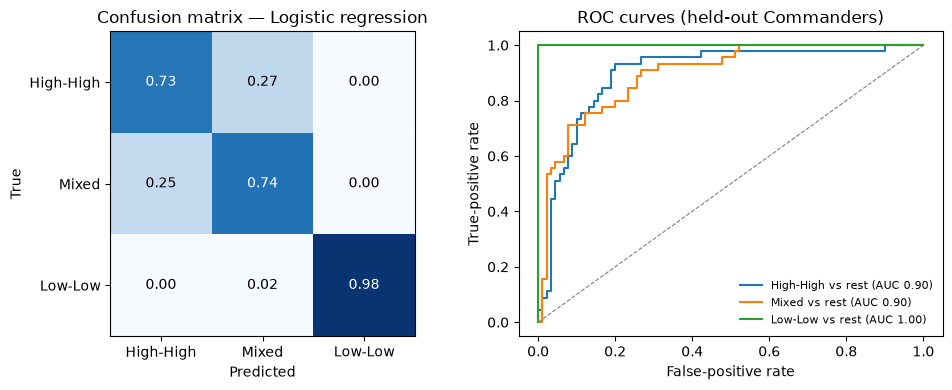

,pred High-High,pred Mixed,pred Low-Low
true High-High,0.73,0.27,0.00
true Mixed,0.25,0.74,0.00
true Low-Low,0.00,0.02,0.98


In [9]:
main = res_3way[SELECTED]
cms = np.array([confusion_matrix(main["y"], p, normalize="true") for p in main["preds"]])
cm = pd.DataFrame(cms.mean(axis=0), index=[f"true {c}" for c in CLASS_NAMES],
                  columns=[f"pred {c}" for c in CLASS_NAMES])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.imshow(cm.values, cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm.values[i, j]:.2f}", ha="center", va="center",
                color="white" if cm.values[i, j] > 0.6 else "black")
ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES)
ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Confusion matrix — {SELECTED}")

ax = axes[1]
for k, name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(main["y"] == k, main["proba"][:, k])
    ax.plot(fpr, tpr, label=f"{name} vs rest (AUC {roc_auc_score(main['y'] == k, main['proba'][:, k]):.2f})")
ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=0.8)
ax.set_xlabel("False-positive rate"); ax.set_ylabel("True-positive rate")
ax.set_title("ROC curves (held-out Commanders)"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig("figures/01_reliability_eye_tracking/confusion_roc.png", dpi=200); plt.show()
cm.round(2)

## 6. Interpretation (selected model)

The interpretation model uses, for each hyperparameter, the **median of the values chosen across the outer folds**
(the setting the nested procedure typically picked). A single grid search on all Commanders is unstable when
performance is nearly flat across the grid, as it is here. Importance and SHAP values are computed on held-out Commanders.

### 6a. Permutation importance by feature family

For each outer fold, the model is trained on the training Commanders; then one feature **family** is shuffled in the
test Commanders' data and the drop in AUC is recorded. Families are shuffled together because their members are
correlated. A drop near 0 means the model does not depend on that family — it can still be informative if another
family carries the same information.

In [10]:
import ast

def interpretation_model(model_name, result):
    # Per-hyperparameter (lower) median of the values chosen in the outer folds
    est, grid = MODELS[model_name]
    chosen = [ast.literal_eval(k) for k, n in result["chosen"].items() for _ in range(n)]
    params = {}
    for p in grid:
        vals = sorted(c[p] for c in chosen)
        params[p] = vals[(len(vals) - 1) // 2]
    return clone(est).set_params(**params), params

model_3way, params_3way = interpretation_model(SELECTED, res_3way[SELECTED])
print(SELECTED, "settings for interpretation:", params_3way)

families = {
    "Dwell share (N, S)":           ["North_dwell_frac", "South_dwell_frac"],
    "UAV fixation rate (N, S)":     ["North_fix_rate", "South_fix_rate"],
    "UAV fixation duration (N, S)": ["North_fix_dur_mean", "South_fix_dur_mean"],
    "Pupil (mean, SD)":             ["pupil_mean", "pupil_sd"],
    "Blinks":                       ["blink_frac"],
    "Overall fixations":            ["fix_rate", "fix_dur_mean"],
    "Saccades":                     ["sac_rate", "sac_amp_mean", "sac_peakvel_px_mean", "sac_dur_mean"],
    "Entropy (SGE, GTE)":           ["SGE", "GTE"],
    "Transitions & switches":       ["p_N_to_S", "p_S_to_N", "NS_switch_rate"],
}
families_c = {k: [c + "_c" for c in v] for k, v in families.items()}


def heldout_importance(model, df, features, target, groups_of_cols, n_cv_repeats=5, n_shuffles=20):
    X, y, g = df[features], df[target], df["ID"]
    scorer = get_scorer("roc_auc" if y.nunique() == 2 else "roc_auc_ovr")
    rng = np.random.default_rng(0)
    rows = []
    for rep in range(n_cv_repeats):
        for tr, te in GroupKFold(n_splits=5, shuffle=True, random_state=rep).split(X, y, g):
            m = clone(model).fit(X.iloc[tr], y.iloc[tr])
            X_te, y_te = X.iloc[te], y.iloc[te]
            base_score = scorer(m, X_te, y_te)
            drops = {}
            for name, cols in groups_of_cols.items():
                d = []
                for _ in range(n_shuffles):
                    X_shuf = X_te.copy()
                    X_shuf[cols] = X_shuf[cols].to_numpy()[rng.permutation(len(X_shuf))]
                    d.append(base_score - scorer(m, X_shuf, y_te))
                drops[name] = np.mean(d)
            rows.append(drops)
    imp = pd.DataFrame(rows)
    return (pd.DataFrame({"AUC_drop": imp.mean(), "SD": imp.std(), "share_folds_positive": (imp > 0).mean()})
              .sort_values("AUC_drop", ascending=False))


imp_3way = heldout_importance(model_3way, data, X_COLS, "condition", families_c)
imp_3way.round(3)

Logistic regression settings for interpretation: {'logisticregression__C': 0.1}


,AUC_drop,SD,share_folds_positive
"Pupil (mean, SD)",0.054,0.030,1.00
Saccades,0.041,0.028,0.96
Transitions & switches,0.032,0.023,0.92
"Dwell share (N, S)",0.014,0.006,1.00
"UAV fixation duration (N, S)",0.013,0.009,0.96
Blinks,0.011,0.017,0.84
"UAV fixation rate (N, S)",0.011,0.009,0.84
Overall fixations,-0.000,0.006,0.64
"Entropy (SGE, GTE)",-0.004,0.009,0.40


### 6b. SHAP values (held-out Commanders)

SHAP splits each block's prediction into one contribution per feature. Each block's values come from a model trained
without that Commander. Units depend on the model: log-odds for logistic regression and XGBoost, probability for
random forest. For logistic regression, SHAP = coefficient × (value − mean), so it carries the same information as the
coefficients, one block at a time.

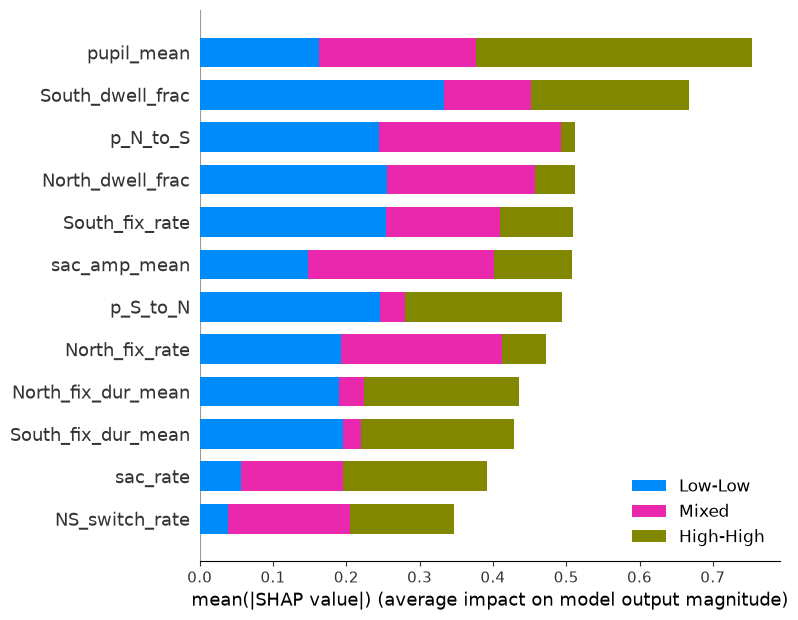

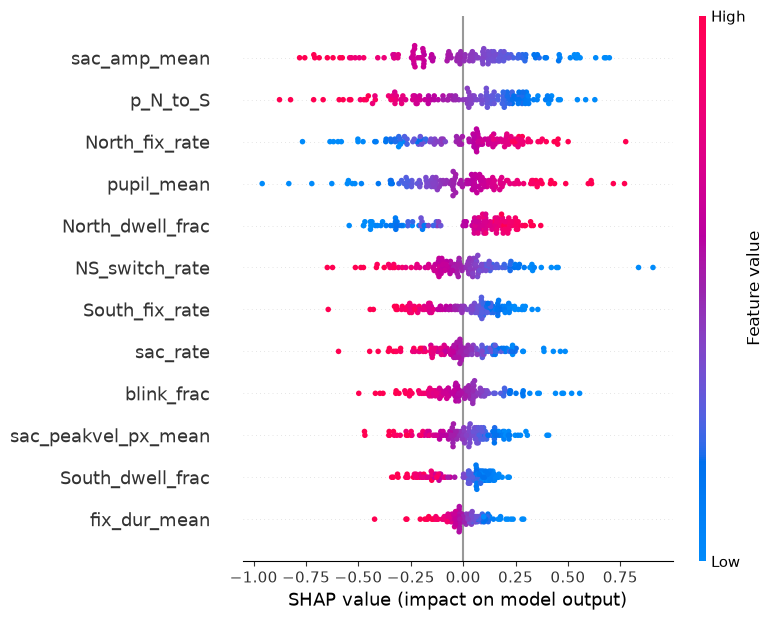

In [11]:
import shap

def oof_shap(model, df, features, target, seed=0):
    X, y, g = df[features], df[target], df["ID"]
    k = y.nunique()
    vals = np.zeros((len(X), X.shape[1], k)) if k > 2 else np.zeros(X.shape)
    for tr, te in GroupKFold(n_splits=5, shuffle=True, random_state=seed).split(X, y, g):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        if hasattr(m, "steps"):                                   # logistic-regression pipeline
            scaler, lr = m[0], m[-1]
            sv = shap.LinearExplainer(lr, scaler.transform(X.iloc[tr])).shap_values(scaler.transform(X.iloc[te]))
        else:                                                     # tree models
            sv = shap.TreeExplainer(m).shap_values(X.iloc[te])
        if isinstance(sv, list):
            sv = np.stack(sv, axis=-1)
        sv = np.asarray(sv)
        if k == 2 and sv.ndim == 3:                               # binary output given per class: keep class 1
            sv = sv[:, :, 1]
        vals[te] = sv
    return vals

shap_3way = oof_shap(model_3way, data, X_COLS, "condition")
X_show = data[X_COLS].rename(columns=lambda c: c.removesuffix("_c"))

plt.figure()
shap.summary_plot([shap_3way[:, :, k] for k in range(3)], X_show, plot_type="bar",
                  class_names=CLASS_NAMES, max_display=12, show=False)
plt.gcf().savefig("figures/01_reliability_eye_tracking/shap_bar_3way.png", dpi=200, bbox_inches="tight"); plt.show()

plt.figure()
shap.summary_plot(shap_3way[:, :, 1], X_show, max_display=12, show=False)     # class 1 = Mixed
plt.gcf().savefig("figures/01_reliability_eye_tracking/shap_beeswarm_mixed.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. Secondary analysis: High-High vs Mixed

Low-Low is distinguished almost perfectly, so the informative question is whether High-High and Mixed can be told apart.
Features are re-centered over each Commander's two blocks (High-High and Mixed only), so each feature is ± half the
Mixed − High-High difference for that person: the model is effectively a paired comparison.
The same model comparison and selection rule are applied.

In [12]:
hm = data[data["Reliability"].isin(["HH", "M"])][["ID", "Reliability"] + FEATURES].copy()
hm = center_within(hm, FEATURES)
hm["is_mixed"] = (hm["Reliability"] == "M").astype(int)

res_hm, tab_hm = compare_models(hm, X_COLS, "is_mixed")
SELECTED_HM, BEST_RAW_HM = select_model(res_hm)
print(f"highest balanced accuracy: {BEST_RAW_HM} | selected by rule: {SELECTED_HM}")
tab_hm.round(3)

highest balanced accuracy: Logistic regression | selected by rule: Logistic regression


,bal_acc,bal_acc_SD,macro_F1,AUC,AUC_SD,train_bal_acc,train_test_gap
Baseline,0.500,0.000,0.333,0.500,0.000,0.500,0.000
Logistic regression,0.791,0.041,0.791,0.805,0.030,0.927,0.136
Random forest,0.767,0.020,0.767,0.841,0.018,0.911,0.144
XGBoost,0.749,0.062,0.749,0.805,0.034,0.922,0.173


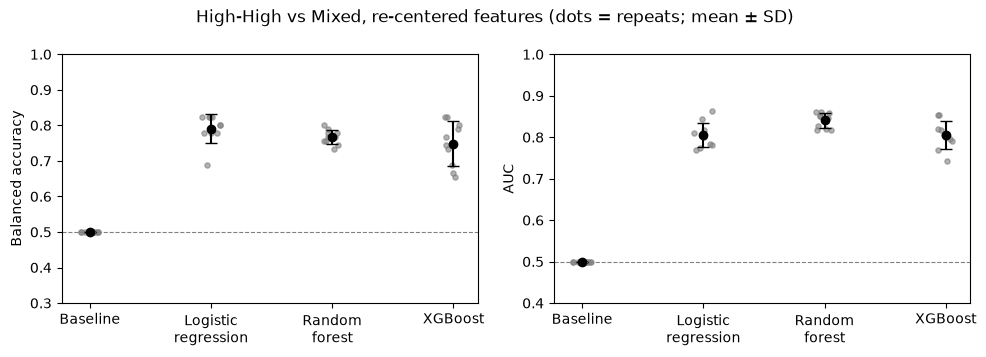

,bal_acc_diff,bal_acc_diff_min,bal_acc_diff_max,AUC_diff,repeats_better_or_equal_%
Logistic regression,0.000,0.000,0.000,0.000,100.0
Random forest,-0.024,-0.056,0.044,0.036,10.0
XGBoost,-0.042,-0.144,0.056,-0.000,40.0


In [13]:
plot_comparison(res_hm, "High-High vs Mixed, re-centered features", "figures/01_reliability_eye_tracking/model_comparison_HH_vs_M.png")
paired_differences(res_hm).round(3)

In [14]:
model_hm, params_hm = interpretation_model(SELECTED_HM, res_hm[SELECTED_HM])
print(SELECTED_HM, "settings for interpretation:", params_hm)
imp_hm = heldout_importance(model_hm, hm, X_COLS, "is_mixed", families_c)
imp_hm.round(3)

Logistic regression settings for interpretation: {'logisticregression__C': 0.1}


,AUC_drop,SD,share_folds_positive
"Pupil (mean, SD)",0.100,0.072,1.00
Transitions & switches,0.092,0.076,0.88
Saccades,0.090,0.071,0.88
"UAV fixation rate (N, S)",0.013,0.030,0.72
"UAV fixation duration (N, S)",0.008,0.027,0.64
Blinks,0.001,0.014,0.52
Overall fixations,-0.003,0.017,0.28
"Entropy (SGE, GTE)",-0.004,0.024,0.40
"Dwell share (N, S)",-0.009,0.020,0.32


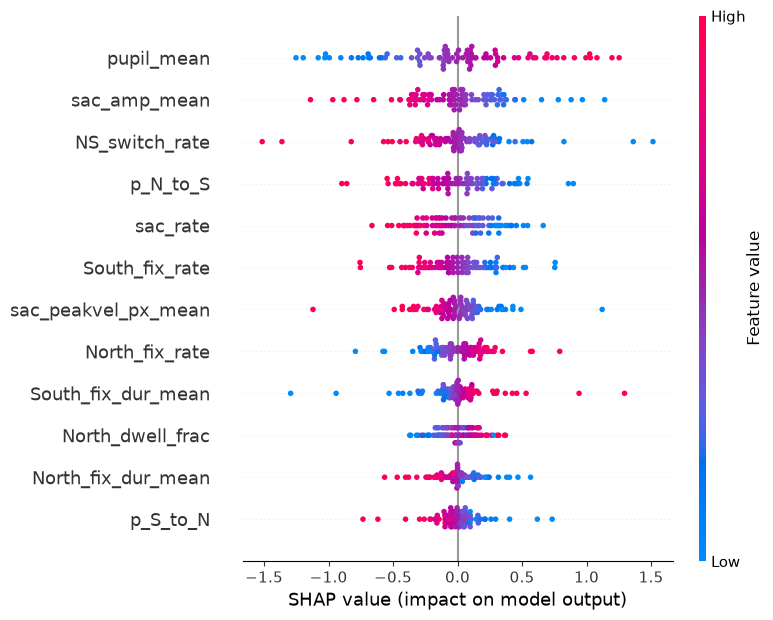

In [15]:
shap_hm = oof_shap(model_hm, hm, X_COLS, "is_mixed")
plt.figure()
shap.summary_plot(shap_hm, hm[X_COLS].rename(columns=lambda c: c.removesuffix("_c")), max_display=12, show=False)
plt.gcf().savefig("figures/01_reliability_eye_tracking/shap_beeswarm_HH_vs_M.png", dpi=200, bbox_inches="tight"); plt.show()

## 8. Feature-level linear mixed-effects models (descriptive, not part of the classifier)

One linear mixed-effects model (LMM) per feature, testing whether it differs between conditions.
For every feature (not only those the model relies on — testing only model-selected features would be circular):
`feature ~ condition + (1 | Commander)`, maximum likelihood, features in SD units. The omnibus condition effect is a
likelihood-ratio test (2 df); pairwise contrasts are Wald tests. Bonferroni: α = .05 / 20 for the omnibus test,
α = .05 / 60 for pairwise contrasts. Uses the raw (uncentered) features; the random intercept handles person differences.

In [16]:
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)


def lmm_by_condition(df, features):
    rows = []
    d = df.copy()
    d["Reliability"] = pd.Categorical(d["Reliability"], ["HH", "M", "LL"])
    for f in features:
        d["z"] = (d[f] - d[f].mean()) / d[f].std()
        full = smf.mixedlm("z ~ C(Reliability)", d, groups=d["ID"]).fit(reml=False)
        null = smf.mixedlm("z ~ 1", d, groups=d["ID"]).fit(reml=False)
        lrt = 2 * (full.llf - null.llf)
        b, names = full.params, full.model.exog_names
        r = np.zeros((1, len(names)))
        r[0, names.index("C(Reliability)[T.LL]")], r[0, names.index("C(Reliability)[T.M]")] = 1, -1
        m_ll = full.t_test(r)
        rows.append({"feature": f, "LRT_chi2": lrt, "p_omnibus": stats.chi2.sf(lrt, 2),
                     "M_minus_HH": b["C(Reliability)[T.M]"], "p_M_HH": full.pvalues["C(Reliability)[T.M]"],
                     "LL_minus_HH": b["C(Reliability)[T.LL]"], "p_LL_HH": full.pvalues["C(Reliability)[T.LL]"],
                     "LL_minus_M": float(m_ll.effect[0]), "p_LL_M": float(m_ll.pvalue)})
    res = pd.DataFrame(rows).set_index("feature")
    k = len(features)
    res["sig_omnibus"] = res["p_omnibus"] < 0.05 / k
    for c in ["p_M_HH", "p_LL_HH", "p_LL_M"]:
        res[c + "_sig"] = res[c] < 0.05 / (k * 3)
    return res.sort_values("p_omnibus")


lmm = lmm_by_condition(data, FEATURES)
lmm.round(4)

,LRT_chi2,p_omnibus,M_minus_HH,p_M_HH,LL_minus_HH,p_LL_HH,LL_minus_M,p_LL_M,sig_omnibus,p_M_HH_sig,p_LL_HH_sig,p_LL_M_sig
feature,,,,,,,,,,,,
South_dwell_frac,186.4796,0.0000,-0.0822,0.2727,1.5792,0.0000,1.6614,0.0000,True,False,True,True
North_dwell_frac,136.0768,0.0000,0.1090,0.3059,-1.5564,0.0000,-1.6654,0.0000,True,False,True,True
p_N_to_S,113.6453,0.0000,-0.3354,0.0006,1.0742,0.0000,1.4096,0.0000,True,True,True,True
South_fix_rate,97.6784,0.0000,-0.2116,0.0318,1.0129,0.0000,1.2245,0.0000,True,False,True,True
p_S_to_N,89.2229,0.0000,-0.1618,0.1622,-1.3108,0.0000,-1.1490,0.0000,True,False,True,True
North_fix_rate,77.9335,0.0000,0.1338,0.2109,-0.9580,0.0000,-1.0919,0.0000,True,False,True,True
South_fix_dur_mean,44.4782,0.0000,0.1211,0.2295,0.7139,0.0000,0.5928,0.0000,True,False,True,True
sac_peakvel_px_mean,44.4560,0.0000,-0.1303,0.0596,0.3748,0.0000,0.5050,0.0000,True,False,True,True
sac_amp_mean,41.3809,0.0000,-0.1726,0.0317,0.3953,0.0000,0.5679,0.0000,True,False,True,True


## Notes and limitations

- **Scenario confound.** Each reliability condition used one fixed scenario video, so condition and video content are
  confounded; classification shows that gaze differs between the three scenario blocks, not that gaze detects
  automation reliability as such.
- **Centering is optimistic for deployment.** It uses each Commander's data from all three conditions; a real-time system
  would not have that.
- **Sample size.** 45 Commanders; differences of about ±0.02 between models or feature sets are within split-to-split variation.
- **Saccades** are Pupil Cloud inter-fixation gaps, not detected from eye velocity; peak velocity is in scene-camera px/s.
  Saccades shorter than 40 ms are partly lost on the 25 Hz grid (rate undercounted, mean amplitude biased up).
- **Event filters** (fixation 80–4000 ms, saccade ≤ 120 ms) are adopted from the literature, not validated on this dataset.